# 49. Mechanism of the HGB spectral warning gain: four integrated experiments (BTC spot)

Here I run four experiments on the onset-anchored gain of HGB with the spectral feature on BTCUSDT spot data, reusing notebooks 47 and 48 for the model fitting and the baseline scheduler. This is a forensic post hoc analysis, not a validation of predictive superiority.

1. HGB threshold ties and score plateaus: scores equal to the cutoff, tied candidate and alert counts, and the sensitivity of the fixed cutoff to `>=` versus strict `>`.
2. Alert timing alignment: one-to-one time matching of alerts at 0, 5, 15, 30 and 60 minutes, and event-level timing for the eight onset catches that only HGB_HS makes.
3. Full-calendar spectral replacement replay: I fix `z_hs` at its 2021 training median at every 2022 calibration minute and every development minute (2023 to April 2026), recompute all HGB_HS scores and rerun the whole policy (20 alerts per month, 240-minute cooldown), once with the frozen 2022 threshold and once with a threshold I recalibrate on 2022 only. I refit neither models nor hyperparameters; this is a noncausal intervention on a fixed trained model.
4. Separate-period evaluation: (a) an optional retrospective stress replay on May to November 2026, a period I have already inspected elsewhere and therefore not an unused holdout; (b) an evaluation on a genuinely unused period from separately supplied BTC spot data with a manifest, which excludes the 2018–2026 periods already examined and the preregistered prospective window 2026-12-01 to 2027-12-01.

I first reproduce the 83 four-hour events; the 9 and 16 onset-anchored and 13 and 12 breach-anchored pre-onset catches of HGB Base and HGB+HS; and the 800 development alerts and 240 calibration alerts in 2022 of each. I selected the onset-anchored 9→16 difference after examining the development outcomes, and the primary breach-anchored screen of notebook 47 failed; I report all results. Inputs: `MyDrive/btc_lead_cost_results_77months_spot/cache` and optionally the notebook 47 output. Results folder: `spectral_mechanism_four_tests_v1`. My cache ends on 2026-05-01, so part (a) has the status `NOT_AVAILABLE`; no data yet exist for the independent evaluation, so part (b) has not run; its earliest start of 2027-12-01 avoids overlap with the registered 2026-12 to 2027-12 test.

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])

try:
    from numba import njit
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab. Configure ROOT manually to run with local files.')

ROOT = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
CACHE = ROOT/'cache'
REPRO47 = ROOT/'spectral_nonlinear_interactions_v1'
OUT = ROOT/'spectral_mechanism_four_tests_v1'
OUT.mkdir(parents=True, exist_ok=True)
NS = 60*10**9
T0 = pd.Timestamp('2021-01-01', tz='UTC').value
T1 = pd.Timestamp('2022-01-01', tz='UTC').value
T2 = pd.Timestamp('2023-01-01', tz='UTC').value
E0 = pd.Timestamp('2023-01-01', tz='UTC').value
E1 = pd.Timestamp('2026-05-01', tz='UTC').value
LEAD_MIN, LEAD_MAX = 30, 240
COOLDOWN = 240
BUDGET_MONTH, BUDGET_YEAR = 20, 240
SPEC = {
    'notebook': '47', 'status': 'exploratory_posthoc',
    'source': 'BTC spot frozen cache', 'train': '2021',
    'target': '4% breach 30-240 min ahead',
    'threshold_calibration': '2022_unlabeled',
    'evaluation': '2023-01 through 2026-04',
    'models': ['Base_Logit','HS_Linear','HS_Interactions','HGB_Base','HGB_HS'],
    'interaction_features': ['z_hs*z_vol','z_hs*(tsr-0.5)','z_hs^2'],
    'clip': 6.0,
    'HGB': dict(max_iter=100, max_leaf_nodes=7, learning_rate=0.05,
                min_samples_leaf=100, l2_regularization=5.0, max_bins=127,
                early_stopping=False, random_state=20261147,
                class_weight='balanced_via_sample_weight'),
    'comparisons': [('HS_Linear','HS_Interactions'),('HGB_Base','HGB_HS')],
    'lead_minutes': [30,240], 'monthly_cap': 20,
    'annual_cap': 240, 'cooldown_minutes': 240,
    'primary': '4h breach-anchored pre-onset catches per 100 alerts',
    'secondary': '4h within-RV-decile pre-onset AUC; onset-anchor and H=1440 descriptive',
    'stop_go': {'within_rv_decile_auc_gain':0.02,
                'pre_catches_per_100_alerts_gain':0.5},
    'selection_note': 'Do not choose a winner from these repeatedly inspected development outcomes',
    'no_holdout_or_prospective_inputs': True
}
(OUT/'49_reproduction_SPEC.json').write_text(json.dumps(SPEC,indent=2))
print('Output:',OUT)

Mounted at /content/drive
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_mechanism_four_tests_v1


## 1. Spot data and the event catalog

I use only BTC spot one-minute parquets and existing non-anticipating features; `z_hs` is the notebook 01 FFT statistic, not a new spectral construction, and future event times enter only as training labels, never as predictors.

In [2]:
for p in [CACHE/'BTCUSDT_1m_regularized.parquet', CACHE/'btc_signals_1m.parquet', CACHE/'DATA_SOURCE.json']:
    if not p.is_file():
        raise FileNotFoundError(f'Required frozen spot cache missing: {p}')
source = json.loads((CACHE/'DATA_SOURCE.json').read_text())
assert source.get('venue')=='spot', 'The cache must be BTC SPOT; no futures substitute.'
px = pd.read_parquet(CACHE/'BTCUSDT_1m_regularized.parquet').sort_index()
sg = pd.read_parquet(CACHE/'btc_signals_1m.parquet', columns=['z_vol','tsr','z_hs']).sort_index()
for d in (px, sg):
    assert isinstance(d.index, pd.DatetimeIndex) and d.index.tz is not None
    d.index = d.index.tz_convert('UTC')
assert px.index.equals(sg.index), 'Price/signal minute indexes differ'
T = px.index.asi8
assert np.all(np.diff(T)==NS), 'Index is not a complete one-minute grid'
close = px.close.to_numpy(dtype=float)
volume = px.volume.to_numpy(dtype=float)
X = sg[['z_vol','tsr','z_hs']].to_numpy(dtype=float)
valid = (np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
         np.isfinite(X).all(axis=1)&(X[:,1]>=0)&(X[:,1]<=1))
print('rows',len(T),'train valid',int((valid&(T>=T0)&(T<T1)).sum()),'eval valid',int((valid&(T>=E0)&(T<E1)).sum()))

def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory: continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi],'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    if not rows: raise RuntimeError('Event catalog empty')
    return pd.DataFrame(rows)

CAT = {h:price_only_catalog(close,volume,px.index,H=h) for h in (240,1440)}
EVAL = {h:CAT[h].loc[(CAT[h].breach_utc.astype('int64')>=E0+LEAD_MAX*NS)&
                             (CAT[h].breach_utc.astype('int64')<E1)].copy().reset_index(drop=True)
        for h in (240,1440)}
# Onset-anchored evaluation needs a complete onset-240 ... onset-30 window.
EVAL_ON = {h: EVAL[h].loc[EVAL[h].onset_1pct_utc.astype('int64') >= E0 + LEAD_MAX*NS].reset_index(drop=True)
           for h in (240,1440)}
# Mandatory guard against the reference 4-hour development event count
assert len(EVAL[240])==83, f'Expected 83 development events at H=240, found {len(EVAL[240])}'
assert len(EVAL[1440])==218, f'Expected 218 events at H=1440, found {len(EVAL[1440])}'
# Optional: exact timestamp comparison with notebook 2
ref = ROOT/'event_definition_eligibility_audit'/'price_only_event_catalog.csv'
if ref.is_file():
    q = pd.read_csv(ref)
    for c in ('peak_utc','onset_1pct_utc','breach_utc','confirmed_utc'):
        a = pd.to_datetime(q[c],utc=True).astype('int64').to_numpy()
        b = CAT[240][c].astype('int64').to_numpy()
        assert np.array_equal(a,b), f'Notebook 2 mismatch for {c}'
    print('PASS: notebook-2 event timestamps reproduced.')

# Labels from the next qualifying event timestamp (same searchsorted convention as notebook 41).
def future_label(T, events_ns):
    z=np.sort(np.asarray(events_ns,dtype=np.int64))
    positions=np.searchsorted(z,T+LEAD_MIN*NS,side='left')
    y=np.zeros(len(T),dtype=np.int8)
    good=positions<len(z)
    y[good]=(z[positions[good]]<=T[good]+LEAD_MAX*NS).astype(np.int8)
    return y

cat4=CAT[240]
y_breach = future_label(T,cat4.breach_utc.astype('int64').to_numpy())
y_onset = future_label(T,cat4.onset_1pct_utc.astype('int64').to_numpy())
# No retrospective classification rule is used as a runtime signal. During onset training,
# remove confirmed-event in-progress minutes from the negative training examples.
in_progress = np.zeros(len(T),bool)
for e in cat4.itertuples(index=False):
    a=np.searchsorted(T,e.onset_1pct_utc.value,'left')
    b=np.searchsorted(T,e.confirmed_utc.value,'right')
    in_progress[a:b]=True
TRAIN = valid &(T>=T0)&(T<T1-(LEAD_MAX+5)*NS)
TRAIN_ONSET = TRAIN & ~in_progress
CAL = valid &(T>=T1)&(T<T2)
DEV = valid &(T>=E0)&(T<E1-(LEAD_MAX+5)*NS)
print('2021 breach positive minutes:',int(y_breach[TRAIN].sum()))
print('2021 onset positive minutes:',int(y_onset[TRAIN_ONSET].sum()))
if not (y_breach[TRAIN].sum()>50 and y_onset[TRAIN_ONSET].sum()>50):
    raise RuntimeError('Insufficient training positives: inspect event labels and cache.')

rows 3329280 train valid 524332 eval valid 1750857
PASS: notebook-2 event timestamps reproduced.
2021 breach positive minutes: 18779
2021 onset positive minutes: 18771


## 2. Five fitted models, no tuning on development data

The logistic interaction arms add fixed polynomial products, and the HGB arms share one architecture and differ only in whether they include `z_hs`. I balance classes with training sample weights and disable HGB early stopping.

In [3]:
# Five arms. All use the same breach target and TRAIN mask.
# This isolates the predictor form, unlike comparisons that also change the target.
CLIP=6.0
zv=np.clip(X[:,0],-CLIP,CLIP)
ts=X[:,1]
hs=np.clip(X[:,2],-CLIP,CLIP)
# Fit the baseline M0 and the linear z_hs ablation on the untouched raw predictors.
X_INTERACT=np.column_stack([X[:,0],X[:,1],X[:,2],hs*zv,hs*(ts-.5),hs*hs])
assert np.isfinite(X_INTERACT[valid]).all(), 'Feature construction produced non-finite observations'

LOGIT_BASE=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_HS=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_INTER=make_pipeline(StandardScaler(),LogisticRegression(
    C=0.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
LOGIT_BASE.fit(X[TRAIN][:,:2],y_breach[TRAIN])
LOGIT_HS.fit(X[TRAIN],y_breach[TRAIN])
LOGIT_INTER.fit(X_INTERACT[TRAIN],y_breach[TRAIN])

# Keep baseline guard from notebook 46 / notebook 16 if present.
frozen=ROOT/'methods_definitions_v1'/'METHODS_FROZEN.json'
if frozen.is_file():
    f=json.loads(frozen.read_text())
    cfg=f['configs']['M0_VF_logit|4pct']
    assert np.allclose(LOGIT_BASE[-1].coef_.ravel(),cfg['coef'],rtol=1e-6,atol=1e-9), 'M0 coefficient mismatch'
    assert np.isclose(LOGIT_BASE[-1].intercept_[0],cfg['intercept'],rtol=1e-6,atol=1e-9), 'M0 intercept mismatch'
    print('PASS: frozen M0 logistic parameters')
else:
    print('Warning: frozen M0 file missing; the AUC and alert guards still apply')

# Small nonlinear model: exact same hyperparameters with vs without spectral input.
# HGB supports sample_weight in all relevant sklearn releases; avoid version-dependent class_weight.
_,cnt=np.unique(y_breach[TRAIN],return_counts=True)
n_pos=int(y_breach[TRAIN].sum());n_neg=int(TRAIN.sum()-n_pos)
assert n_pos>50 and n_neg>n_pos
train_w=np.where(y_breach[TRAIN]==1,(n_pos+n_neg)/(2*n_pos),(n_pos+n_neg)/(2*n_neg))
def fixed_hgb():
    return HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=7,
        learning_rate=0.05,min_samples_leaf=100,l2_regularization=5.0,
        max_bins=127,early_stopping=False,random_state=20261147)
HGB_BASE=fixed_hgb();HGB_HS=fixed_hgb()
HGB_BASE.fit(X[TRAIN][:,:2],y_breach[TRAIN],sample_weight=train_w)
HGB_HS.fit(X[TRAIN],y_breach[TRAIN],sample_weight=train_w)
MODELS={
 'Base_Logit':(LOGIT_BASE,'base'),
 'HS_Linear':(LOGIT_HS,'hs'),
 'HS_Interactions':(LOGIT_INTER,'interactions'),
 'HGB_Base':(HGB_BASE,'base'),
 'HGB_HS':(HGB_HS,'hs'),
}
print('Training count',int(TRAIN.sum()),'positive labels',int(n_pos))

# Predict in chunks, only for 2022 calibration + 2023-2026 development.
SCORE={}
mask_pred=CAL|DEV
indices=np.flatnonzero(mask_pred)
for name,(model,which) in MODELS.items():
    scores=np.full(len(T),np.nan,dtype=np.float64)
    for block in np.array_split(indices,max(1,int(np.ceil(len(indices)/180000)))):
        xx= X_INTERACT[block] if which=='interactions' else (X[block,:2] if which=='base' else X[block])
        scores[block]=model.predict_proba(xx)[:,1]
    assert np.isfinite(scores[mask_pred]).all(),f'{name}: nonfinite scores'
    SCORE[name]=scores
    print(name,'score computed on',len(indices),'2022+development minutes',flush=True)
# Free the largest temporary arrays; the score arrays and base inputs remain.
del X_INTERACT,zv,ts,hs

PASS: frozen M0 logistic parameters
Training count 524087 positive labels 18779
Base_Logit score computed on 2276212 2022+development minutes
HS_Linear score computed on 2276212 2022+development minutes
HS_Interactions score computed on 2276212 2022+development minutes
HGB_Base score computed on 2276212 2022+development minutes
HGB_HS score computed on 2276212 2022+development minutes


## 3. Calendar scheduler and unlabeled 2022 calibration

The scheduler code is the same as in notebook 46. I report exact alert counts and differences per 100 alerts, so no candidate gains credit for sending more alerts.

In [4]:
@njit(cache=False)
def calendar_core(t,elig,years,months,B,cap,cooldown_ns):
    out=np.empty(len(t),dtype=np.int64)
    n=0; month_count=0; year_count=0; last_m=-1; last_y=-1; last=-(2**62)
    for i in range(len(t)):
        if not elig[i]: continue
        yr=years[i]; mo=months[i]; ti=t[i]
        if yr!=last_y: year_count=0; last_y=yr
        if mo!=last_m: month_count=0; last_m=mo
        if month_count>=cap or year_count>=B or ti-last<cooldown_ns: continue
        out[n]=ti;n+=1;month_count+=1;year_count+=1;last=ti
    return out[:n].copy()

def scheduler(time_ns,score,threshold):
    tm=pd.to_datetime(time_ns,utc=True)
    yrs=np.asarray(tm.year,dtype=np.int64)
    months=np.asarray(tm.year*12+tm.month,dtype=np.int64)
    e=np.asarray(np.isfinite(score)&(score>=threshold),dtype=np.bool_)
    return calendar_core(np.asarray(time_ns,np.int64),e,yrs,months,BUDGET_YEAR,BUDGET_MONTH,COOLDOWN*NS)

def score_grid(sc):
    Q=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
    return np.unique(np.r_[np.nextafter(sc.min(),-np.inf),np.quantile(sc,Q),np.nextafter(sc.max(),np.inf)])

def calibrate(time_ns,sc):
    rows=[]
    for th in score_grid(sc):
        count=len(scheduler(time_ns,sc,th))
        rows.append((float(th),count,int(np.count_nonzero(sc>=th))))
    d=pd.DataFrame(rows,columns=['threshold','cal_alerts','raw_candidates'])
    row=d[d.cal_alerts==d.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(row.threshold),int(row.cal_alerts),d

T_CAL=T[CAL];T_DEV=T[DEV]
THR={}; ALARMS={}; CAL_COUNTS={}
for name in MODELS:
    thr,ncal,_=calibrate(T_CAL,SCORE[name][CAL])
    THR[name]=thr;CAL_COUNTS[name]=ncal
    ALARMS[name]=scheduler(T_DEV,SCORE[name][DEV],thr)
    print(f'{name:14s} 2022 cal alerts={ncal:3d}  threshold={thr:.6g}  development alerts={len(ALARMS[name])}')
assert all(len(x)<=40*20 for x in ALARMS.values()),'Exceeded maximum 40-month 20-per-month budget'

Base_Logit     2022 cal alerts=240  threshold=0.669899  development alerts=800
HS_Linear      2022 cal alerts=240  threshold=0.671414  development alerts=800
HS_Interactions 2022 cal alerts=240  threshold=0.667268  development alerts=800
HGB_Base       2022 cal alerts=240  threshold=0.621315  development alerts=800
HGB_HS         2022 cal alerts=240  threshold=0.626659  development alerts=800


## 4. Pre-onset catches

The primary endpoint is the 4-hour breach-anchored judging window `[breach - 240, breach - 30]` with alerts before onset; the onset-anchored window and the 24-hour definition are secondary. These are different tasks, so a larger onset-anchored count is not an improvement on the breach-anchored endpoint.

In [5]:
def event_catches(events, alerts, anchor='breach'):
    alert=np.asarray(alerts,dtype=np.int64)
    rows=[]
    for e in events.itertuples(index=False):
        on=e.onset_1pct_utc.value;b=e.breach_utc.value
        anchor_ns=on if anchor=='onset' else b
        lo=anchor_ns-LEAD_MAX*NS; hi=anchor_ns-LEAD_MIN*NS
        l=np.searchsorted(alert,lo,side='left')
        r=np.searchsorted(alert,hi,side='right')
        eligible=alert[l:r]
        good=eligible[eligible<on]
        rows.append((e.event_id,len(good)>0,(on-int(good[0]))/NS if len(good) else np.nan))
    return pd.DataFrame(rows,columns=['event_id','hit','lead_to_onset_minutes'])

rows=[];HITS={}
for h in (240,1440):
    for name in MODELS:
        for anchor in ('breach','onset'):
            E = EVAL_ON[h] if anchor=='onset' else EVAL[h]
            hit=event_catches(E,ALARMS[name],anchor)
            HITS[(h,name,anchor)]=hit
            n=len(ALARMS[name]);k=int(hit.hit.sum())
            rows.append({'H':h,'model':name,'anchor':anchor,'events':len(E),
                         'alerts':n,'pre_catches':k,'pre_recall':k/len(E),
                         'pre_catches_per_100_alerts':100*k/n if n else np.nan,
                         'median_lead_minutes':hit.lead_to_onset_minutes.median(),
                         '2022_calibration_alerts':CAL_COUNTS[name]})
RESULTS=pd.DataFrame(rows)
from IPython.display import display
display(RESULTS)

,H,model,anchor,events,alerts,pre_catches,pre_recall,pre_catches_per_100_alerts,median_lead_minutes,2022_calibration_alerts
0,240,Base_Logit,breach,83,800,22,0.265060,2.750,25.0,240
1,240,Base_Logit,onset,83,800,15,0.180723,1.875,72.0,240
2,240,HS_Linear,breach,83,800,18,0.216867,2.250,42.5,240
3,240,HS_Linear,onset,83,800,13,0.156627,1.625,64.0,240
4,240,HS_Interactions,breach,83,800,14,0.168675,1.750,60.5,240
5,240,HS_Interactions,onset,83,800,14,0.168675,1.750,94.0,240
6,240,HGB_Base,breach,83,800,13,0.156627,1.625,27.0,240
7,240,HGB_Base,onset,83,800,9,0.108434,1.125,97.0,240
8,240,HGB_HS,breach,83,800,12,0.144578,1.500,65.5,240
9,240,HGB_HS,onset,83,800,16,0.192771,2.000,134.5,240


## 5. Reproduction and 83-event hit matrix

With the same trained models, pre-onset definitions, fixed 2022 threshold calibration and 800 alerts as in notebook 47, I reproduce the 9/16 onset-anchored and 13/12 breach-anchored catches and record in a per-event table the eight newly caught events and the one lost event.

In [6]:
# Strict reproduction guards before any mechanism analysis.
def n_hit(h, model, anchor):
    return int(RESULTS.query('H == @h and model == @model and anchor == @anchor').pre_catches.iloc[0])
assert len(ALARMS['HGB_Base']) == len(ALARMS['HGB_HS']) == 800
assert (n_hit(240,'HGB_Base','onset'),n_hit(240,'HGB_HS','onset')) == (9,16)
assert (n_hit(240,'HGB_Base','breach'),n_hit(240,'HGB_HS','breach')) == (13,12)
assert (n_hit(240,'Base_Logit','breach'),n_hit(240,'Base_Logit','onset')) == (22,15)
prior=REPRO47/'1_event_level.csv'
if prior.is_file():
    old=pd.read_csv(prior)
    for name in ('HGB_Base','HGB_HS'):
        for anch in ('breach','onset'):
            cur=n_hit(240,name,anch)
            assert cur == int(old.query('H == 240 and model == @name and anchor == @anch').pre_catches.iloc[0])
    print('PASS: HGB aggregate catches reproduce saved notebook 47')
else:
    print('Warning: saved notebook 47 aggregate unavailable; the hard-coded guards passed')

def qualifying_alerts(e, alert_ns, anchor='onset'):
    on=e.onset_1pct_utc.value;b=e.breach_utc.value
    fixed=on if anchor=='onset' else b
    lo=fixed-LEAD_MAX*NS; hi=fixed-LEAD_MIN*NS
    a=np.asarray(alert_ns,dtype=np.int64)
    left=np.searchsorted(a,lo,'left');right=np.searchsorted(a,hi,'right')
    z=a[left:right]
    return z[z<on]

def iso(ns):
    return pd.Timestamp(int(ns),tz='UTC').isoformat() if ns is not None and pd.notna(ns) else ''

E=EVAL_ON[240]
rows=[]
for e in E.itertuples(index=False):
    b0=qualifying_alerts(e,ALARMS['HGB_Base'],'onset')
    hs=qualifying_alerts(e,ALARMS['HGB_HS'],'onset')
    b0_b=qualifying_alerts(e,ALARMS['HGB_Base'],'breach')
    hs_b=qualifying_alerts(e,ALARMS['HGB_HS'],'breach')
    group='new_only' if len(hs) and not len(b0) else ('base_only' if len(b0) and not len(hs) else ('both' if len(b0) and len(hs) else 'neither'))
    rows.append(dict(event_id=e.event_id,peak_utc=e.peak_utc,onset_utc=e.onset_1pct_utc,
       breach_utc=e.breach_utc,onset_to_breach_min=int(e.onset_to_breach_minutes),
       onset_group=group,base_onset_hit=bool(len(b0)),hs_onset_hit=bool(len(hs)),
       base_breach_hit=bool(len(b0_b)),hs_breach_hit=bool(len(hs_b)),
       base_first_onset_alert_utc=iso(b0[0]) if len(b0) else '',
       hs_first_onset_alert_utc=iso(hs[0]) if len(hs) else '',
       base_onset_lead_min=(e.onset_1pct_utc.value-b0[0])/NS if len(b0) else np.nan,
       hs_onset_lead_min=(e.onset_1pct_utc.value-hs[0])/NS if len(hs) else np.nan,
       hs_alert_before_price_peak=bool(hs[0]<e.peak_utc.value) if len(hs) else False,
       base_alert_before_price_peak=bool(b0[0]<e.peak_utc.value) if len(b0) else False,
       hs_alert_outside_breach_window=bool(len(hs) and not (e.breach_utc.value-LEAD_MAX*NS<=hs[0]<=e.breach_utc.value-LEAD_MIN*NS)),
       hs_alert_to_breach_min=(e.breach_utc.value-hs[0])/NS if len(hs) else np.nan,
    ))
EVENTS=pd.DataFrame(rows)
EVENTS.to_csv(OUT/'1_onset_event_hit_matrix_4h.csv',index=False)
from IPython.display import display
print(EVENTS.onset_group.value_counts().to_string())
assert int((EVENTS.onset_group=='new_only').sum())==8
assert int((EVENTS.onset_group=='base_only').sum())==1
assert int((EVENTS.onset_group=='both').sum())==8
assert int((EVENTS.onset_group=='neither').sum())==66
print('PASS: 8 new-only, 1 base-only, 8 both, 66 neither = 83 events')
display(EVENTS[EVENTS.onset_group.isin(['new_only','base_only'])].sort_values('onset_utc'))


PASS: HGB aggregate catches reproduce saved notebook 47
onset_group
neither      66
new_only      8
both          8
base_only     1
PASS: 8 new-only, 1 base-only, 8 both, 66 neither = 83 events


,event_id,peak_utc,onset_utc,breach_utc,onset_to_breach_min,onset_group,base_onset_hit,hs_onset_hit,base_breach_hit,hs_breach_hit,base_first_onset_alert_utc,hs_first_onset_alert_utc,base_onset_lead_min,hs_onset_lead_min,hs_alert_before_price_peak,base_alert_before_price_peak,hs_alert_outside_breach_window,hs_alert_to_breach_min
3,190,2023-03-09 16:15:00+00:00,2023-03-09 17:02:00+00:00,2023-03-09 20:11:00+00:00,189,new_only,False,True,False,False,,2023-03-09T13:36:00+00:00,NaN,206.0,True,False,True,395.0
9,196,2023-06-05 14:47:00+00:00,2023-06-05 15:25:00+00:00,2023-06-05 17:09:00+00:00,104,new_only,False,True,True,True,,2023-06-05T14:36:00+00:00,NaN,49.0,True,False,False,153.0
15,202,2023-11-09 14:53:00+00:00,2023-11-09 15:23:00+00:00,2023-11-09 16:35:00+00:00,72,base_only,True,False,True,False,2023-11-09T12:48:00+00:00,,155.0,NaN,False,True,False,NaN
17,204,2024-01-03 09:39:00+00:00,2024-01-03 11:07:00+00:00,2024-01-03 12:00:00+00:00,53,new_only,False,True,False,False,,2024-01-03T07:46:00+00:00,NaN,201.0,True,False,True,254.0
42,229,2024-08-05 16:29:00+00:00,2024-08-05 16:34:00+00:00,2024-08-05 19:07:00+00:00,153,new_only,False,True,True,True,,2024-08-05T15:33:00+00:00,NaN,61.0,True,False,False,214.0
50,237,2024-12-05 18:40:00+00:00,2024-12-05 18:59:00+00:00,2024-12-05 22:26:00+00:00,207,new_only,False,True,False,False,,2024-12-05T15:29:00+00:00,NaN,210.0,True,False,True,417.0
59,246,2025-03-03 13:43:00+00:00,2025-03-03 14:35:00+00:00,2025-03-03 14:56:00+00:00,21,new_only,False,True,False,True,,2025-03-03T11:02:00+00:00,NaN,213.0,True,False,False,234.0
62,249,2025-04-02 20:16:00+00:00,2025-04-02 20:22:00+00:00,2025-04-02 21:09:00+00:00,47,new_only,False,True,True,True,,2025-04-02T17:53:00+00:00,NaN,149.0,True,False,False,196.0
76,263,2026-02-02 00:38:00+00:00,2026-02-02 01:09:00+00:00,2026-02-02 03:34:00+00:00,145,new_only,False,True,True,True,,2026-02-01T23:56:00+00:00,NaN,73.0,True,False,False,218.0


## 6. Each rescued onset event

For each newly caught event I locate the actual HGB_HS alert, its lead relative to onset and breach, whether the price peak had already passed, the spectral feature value at that minute, each model's score against its own frozen threshold, and whether its own budget or cooldown blocked the baseline scheduler. I do not compare raw probabilities across models, because their score calibrations differ.

In [7]:
def n_this_month_before(alerts, t_ns):
    dt=pd.Timestamp(int(t_ns),tz='UTC')
    lo=pd.Timestamp(year=dt.year,month=dt.month,day=1,tz='UTC').value
    a=np.asarray(alerts,np.int64)
    return int(np.searchsorted(a,t_ns,side='left')-np.searchsorted(a,lo,side='left'))

def latest_prior(alerts,t_ns):
    a=np.asarray(alerts,np.int64)
    k=np.searchsorted(a,t_ns,side='left')-1
    return int(a[k]) if k>=0 else None

def scheduler_reason(model,alert_ns):
    idx=np.searchsorted(T,alert_ns)
    if idx>=len(T) or T[idx]!=alert_ns or not DEV[idx] or not np.isfinite(SCORE[model][idx]):
        return 'outside_scored_valid_grid'
    if SCORE[model][idx]<THR[model]:
        return 'below_own_threshold'
    previous=latest_prior(ALARMS[model],alert_ns)
    if previous is not None and alert_ns-previous<COOLDOWN*NS:
        return 'blocked_by_own_cooldown'
    if n_this_month_before(ALARMS[model],alert_ns)>=BUDGET_MONTH:
        return 'monthly_alert_budget_exhausted'
    return 'threshold_met_but_not_alerted_CHECK'

# The 2021 median is fixed independently of 2023-2026 outcomes.
TRAIN_HS_MEDIAN=float(np.median(X[TRAIN,2]))
TRAIN_HS_Q10,TRAIN_HS_Q90=np.quantile(X[TRAIN,2],[.1,.9])
assert np.isfinite(TRAIN_HS_MEDIAN)

def hs_spectral_perturbation(t_ns):
    ix=np.searchsorted(T,t_ns)
    x_true=X[ix].reshape(1,-1).copy()
    x_cf=x_true.copy();x_cf[0,2]=TRAIN_HS_MEDIAN
    observed=float(HGB_HS.predict_proba(x_true)[0,1])
    neutral=float(HGB_HS.predict_proba(x_cf)[0,1])
    return observed,neutral,observed-neutral

out=[]
for e in E.itertuples(index=False):
    g=EVENTS.loc[EVENTS.event_id==e.event_id,'onset_group'].iloc[0]
    if g not in ('new_only','base_only'): continue
    # For new-only use HGB_HS actual alert, for base-only use HGB_Base actual alert.
    model='HGB_HS' if g=='new_only' else 'HGB_Base'
    rival='HGB_Base' if g=='new_only' else 'HGB_HS'
    chosen=qualifying_alerts(e,ALARMS[model],'onset')
    assert len(chosen)>0
    t=int(chosen[0]);idx=np.searchsorted(T,t)
    prior=latest_prior(ALARMS[rival],t)
    hscore,nscore,uplift=hs_spectral_perturbation(t)
    # Use a local index slice for speed; no future data enters a model.
    left=np.searchsorted(T,e.onset_1pct_utc.value-LEAD_MAX*NS)
    right=np.searchsorted(T,e.onset_1pct_utc.value-LEAD_MIN*NS,side='right')
    out.append(dict(event_id=e.event_id,group=g,peak_utc=e.peak_utc,
      onset_utc=e.onset_1pct_utc,breach_utc=e.breach_utc,
      onset_to_breach_min=int(e.onset_to_breach_minutes),
      chosen_model=model,chosen_alert_utc=iso(t),
      alert_to_onset_min=(e.onset_1pct_utc.value-t)/NS,
      alert_to_breach_min=(e.breach_utc.value-t)/NS,
      alert_to_peak_min=(e.peak_utc.value-t)/NS,
      actually_before_peak=bool(t<e.peak_utc.value),
      inside_breach_window=bool(e.breach_utc.value-LEAD_MAX*NS<=t<=e.breach_utc.value-LEAD_MIN*NS),
      z_hs=float(X[idx,2]),z_vol=float(X[idx,0]),taker_sell_ratio=float(X[idx,1]),
      base_score=float(SCORE['HGB_Base'][idx]),base_threshold=float(THR['HGB_Base']),
      hs_score=float(SCORE['HGB_HS'][idx]),hs_threshold=float(THR['HGB_HS']),
      base_score_above_threshold=bool(SCORE['HGB_Base'][idx]>=THR['HGB_Base']),
      hs_score_above_threshold=bool(SCORE['HGB_HS'][idx]>=THR['HGB_HS']),
      rival_no_alert_reason=scheduler_reason(rival,t),
      rival_month_alert_count_before=n_this_month_before(ALARMS[rival],t),
      rival_last_alert_distance_min=(t-prior)/NS if prior is not None else np.nan,
      rival_candidate_minutes_in_onset_window=int((np.isfinite(SCORE[rival][left:right])&
            (SCORE[rival][left:right]>=THR[rival])&DEV[left:right]).sum()),
      hs_model_score_at_actual_zhs=hscore,
      hs_model_score_at_training_median_zhs=nscore,
      hs_model_spectral_score_uplift=uplift,
      hs_counterfactual_above_hs_threshold=bool(nscore>=THR['HGB_HS']),
    ))
AUDIT=pd.DataFrame(out).sort_values(['group','onset_utc'])
AUDIT.to_csv(OUT/'2_discordant_event_alert_mechanism.csv',index=False)
print('2021 training z_hs median',TRAIN_HS_MEDIAN,'quantiles',TRAIN_HS_Q10,TRAIN_HS_Q90)
print('Rival non-alert explanations:')
print(AUDIT.groupby(['group','rival_no_alert_reason']).size().to_string())
display(AUDIT[['event_id','group','onset_utc','chosen_alert_utc','alert_to_onset_min','alert_to_breach_min',
  'alert_to_peak_min','actually_before_peak','inside_breach_window','z_hs','z_vol',
  'rival_no_alert_reason','rival_month_alert_count_before',
  'hs_model_spectral_score_uplift','hs_counterfactual_above_hs_threshold']])


2021 training z_hs median -0.07467103749513626 quantiles -1.236089539527893 1.39021372795105
Rival non-alert explanations:
group      rival_no_alert_reason  
base_only  below_own_threshold        1
new_only   below_own_threshold        5
           blocked_by_own_cooldown    3


,event_id,group,onset_utc,chosen_alert_utc,alert_to_onset_min,alert_to_breach_min,alert_to_peak_min,actually_before_peak,inside_breach_window,z_hs,z_vol,rival_no_alert_reason,rival_month_alert_count_before,hs_model_spectral_score_uplift,hs_counterfactual_above_hs_threshold
2,202,base_only,2023-11-09 15:23:00+00:00,2023-11-09T12:48:00+00:00,155.0,227.0,125.0,True,True,1.085575,1.204872,below_own_threshold,20,0.000578,False
0,190,new_only,2023-03-09 17:02:00+00:00,2023-03-09T13:36:00+00:00,206.0,395.0,159.0,True,False,0.132111,0.799446,below_own_threshold,16,0.000000,True
1,196,new_only,2023-06-05 15:25:00+00:00,2023-06-05T14:36:00+00:00,49.0,153.0,11.0,True,True,-0.115453,0.720154,below_own_threshold,7,0.000000,True
3,204,new_only,2024-01-03 11:07:00+00:00,2024-01-03T07:46:00+00:00,201.0,254.0,113.0,True,False,1.830160,0.383967,below_own_threshold,5,0.096494,False
4,229,new_only,2024-08-05 16:34:00+00:00,2024-08-05T15:33:00+00:00,61.0,214.0,56.0,True,True,2.480879,2.529475,blocked_by_own_cooldown,17,-0.027146,True
5,237,new_only,2024-12-05 18:59:00+00:00,2024-12-05T15:29:00+00:00,210.0,417.0,191.0,True,False,1.684690,1.931202,blocked_by_own_cooldown,7,-0.008703,True
6,246,new_only,2025-03-03 14:35:00+00:00,2025-03-03T11:02:00+00:00,213.0,234.0,161.0,True,True,0.100343,0.760213,below_own_threshold,5,0.000000,True
7,249,new_only,2025-04-02 20:22:00+00:00,2025-04-02T17:53:00+00:00,149.0,196.0,143.0,True,True,1.064948,0.427557,below_own_threshold,2,0.070425,False
8,263,new_only,2026-02-02 01:09:00+00:00,2026-02-01T23:56:00+00:00,73.0,218.0,42.0,True,True,1.429423,2.012668,blocked_by_own_cooldown,5,-0.002869,True


## Experiment 1. Score ties, discrete plateaus and strict-cutoff sensitivity

HGB scores are piecewise constant, so quantile-based calibration can pick an exact observed score as the threshold, and ties count as alerts under the frozen `score >= threshold` rule. I measure the tie sizes, check whether the alerts of the eight rescued events sit on a threshold plateau and replay a strict `>` rule at exactly the frozen threshold. The strict replay may issue fewer alerts, so I treat it as a sensitivity analysis, not an equally budgeted improvement.

In [8]:
from IPython.display import display

def threshold_diagnostics(name, mask, sample_label):
    s=np.asarray(SCORE[name][mask],dtype=np.float64)
    th=float(THR[name]); finite=s[np.isfinite(s)]
    uniq,cnt=np.unique(finite,return_counts=True)
    uidx=np.argsort(cnt)[-5:][::-1]
    tie=(finite==th)
    # Report one-ULP adjacency separately from exact equality.
    near=np.abs(finite-th)<=np.spacing(th)*2
    return dict(model=name,period=sample_label,rows_scored=len(finite),unique_score_values=len(uniq),
      cutoff=th,score_min=float(finite.min()),score_max=float(finite.max()),
      equal_cutoff_minutes=int(tie.sum()),equal_cutoff_pct=float(100*tie.mean()),
      within_two_ulp_minutes=int(near.sum()),above_cutoff_minutes=int((finite>th).sum()),
      at_or_above_cutoff_minutes=int((finite>=th).sum()),
      largest_plateau_count=int(cnt.max()),largest_plateau_score=float(uniq[np.argmax(cnt)]),
      five_largest_plateaus='; '.join(f'{uniq[k]:.12f}:{cnt[k]}' for k in uidx))

TIE_TABLE=pd.DataFrame([threshold_diagnostics(m,msk,name)
    for m in ['HGB_Base','HGB_HS'] for msk,name in [(CAL,'cal_2022'),(DEV,'development_2023_2026Apr')]])

TIE_ALERTS=[]
STRICT={}
for model in ['HGB_Base','HGB_HS']:
    th=float(THR[model]);a=ALARMS[model]
    idx=np.searchsorted(T,a)
    alert_s=SCORE[model][idx]
    # The next representable float above th makes `>=` identical to score > th.
    th_strict=float(np.nextafter(th,np.inf))
    strict_cal=scheduler(T_CAL,SCORE[model][CAL],th_strict)
    strict_dev=scheduler(T_DEV,SCORE[model][DEV],th_strict)
    STRICT[model]=strict_dev
    TIE_ALERTS.append(dict(model=model,threshold=th,exact_threshold_alerts=int(np.sum(alert_s==th)),
        exact_threshold_alert_frac=float(np.mean(alert_s==th)),
        ordinary_2022_cal_alerts=CAL_COUNTS[model],strict_2022_cal_alerts=len(strict_cal),
        ordinary_development_alerts=len(a),strict_development_alerts=len(strict_dev),
        standard_onset_catches=int(event_catches(EVAL_ON[240],a,'onset').hit.sum()),
        strict_onset_catches=int(event_catches(EVAL_ON[240],strict_dev,'onset').hit.sum()),
        standard_breach_catches=int(event_catches(EVAL[240],a,'breach').hit.sum()),
        strict_breach_catches=int(event_catches(EVAL[240],strict_dev,'breach').hit.sum())))
TIE_ALERT_SUMMARY=pd.DataFrame(TIE_ALERTS)
rescues=AUDIT.loc[AUDIT.group=='new_only'].copy()
rescues['hs_score_exactly_at_threshold']=(rescues.hs_score==rescues.hs_threshold)
rescues['hs_score_within_2ulp']=np.abs(rescues.hs_score-rescues.hs_threshold)<=2*np.spacing(rescues.hs_threshold)
rescues['base_score_exactly_at_threshold']=(rescues.base_score==rescues.base_threshold)
rescues[['event_id','chosen_alert_utc','hs_score','hs_threshold','hs_score_exactly_at_threshold',
         'hs_score_within_2ulp','base_score','base_threshold']].to_csv(
    OUT/'49_1_rescue_threshold_ties.csv',index=False)
TIE_TABLE.to_csv(OUT/'49_1_score_plateaus.csv',index=False)
TIE_ALERT_SUMMARY.to_csv(OUT/'49_1_strict_threshold_replay.csv',index=False)
print('Score plateau audit:');display(TIE_TABLE.drop(columns=['five_largest_plateaus']))
print('Strict cutoff sensitivity (alert counts can differ):');display(TIE_ALERT_SUMMARY)
print('Rescue events on HGB_HS threshold:',int(rescues.hs_score_exactly_at_threshold.sum()),'of',len(rescues))
assert len(rescues)==8


Score plateau audit:


,model,period,rows_scored,unique_score_values,cutoff,score_min,score_max,equal_cutoff_minutes,equal_cutoff_pct,within_two_ulp_minutes,above_cutoff_minutes,at_or_above_cutoff_minutes,largest_plateau_count,largest_plateau_score
0,HGB_Base,cal_2022,525600,1102,0.621315,0.036370,0.793309,788,0.149924,788,31806,32594,10476,0.578998
1,HGB_Base,development_2023_2026Apr,1750612,1102,0.621315,0.036370,0.793309,2007,0.114646,2007,84970,86977,20615,0.582715
2,HGB_HS,cal_2022,525600,5386,0.626659,0.024994,0.795245,2394,0.455479,2394,31701,34095,30866,0.300793
3,HGB_HS,development_2023_2026Apr,1750612,5844,0.626659,0.024994,0.795245,2827,0.161486,2827,87753,90580,53114,0.445229


Strict cutoff sensitivity (alert counts can differ):


,model,threshold,exact_threshold_alerts,exact_threshold_alert_frac,ordinary_2022_cal_alerts,strict_2022_cal_alerts,ordinary_development_alerts,strict_development_alerts,standard_onset_catches,strict_onset_catches,standard_breach_catches,strict_breach_catches
0,HGB_Base,0.621315,71,0.08875,240,240,800,800,9,10,13,14
1,HGB_HS,0.626659,128,0.16000,240,240,800,800,16,15,12,15


Rescue events on HGB_HS threshold: 3 of 8


## Experiment 2. One-to-one alert timing matching

I match the two 800-alert streams one to one with a sorted two-pointer procedure that maximizes the number of alerts matched within a symmetric tolerance, each alert matching at most once, and record the nearest HGB_Base alert for each of the eight HGB_HS-only event alerts. A nearby alert is not automatically a successful onset warning, since judging windows and cooldown still apply.

In [9]:
def match_alerts_one_to_one(a,b,tolerance_min,return_pairs=True):
    aa=np.asarray(a,dtype=np.int64);bb=np.asarray(b,dtype=np.int64)
    assert np.all(np.diff(aa)>=0) and np.all(np.diff(bb)>=0),'Inputs must be sorted UTC nanoseconds'
    tol=int(tolerance_min)*NS;i=j=0;pairs=[]
    while i<len(aa) and j<len(bb):
        if aa[i] < bb[j]-tol:i+=1
        elif bb[j] < aa[i]-tol:j+=1
        else:
            if return_pairs:pairs.append((int(aa[i]),int(bb[j])))
            else:pairs.append(None)
            i+=1;j+=1
    return pairs

# Synthetic exact-time and near-time guard (a single alert may never be used twice).
syn_a=np.array([100,110,200],np.int64)*NS
syn_b=np.array([105,107,220],np.int64)*NS
assert len(match_alerts_one_to_one(syn_a,syn_b,5))==2
assert len(match_alerts_one_to_one(syn_a,syn_b,10))==2
assert len(match_alerts_one_to_one(syn_a,syn_b,30))==3

TIME_ROWS=[];TIME_PAIRS=[]
for tol in [0,5,15,30,60]:
    pairs=match_alerts_one_to_one(ALARMS['HGB_Base'],ALARMS['HGB_HS'],tol)
    offsets=np.array([(b-a)/NS for a,b in pairs],dtype=float)
    TIME_ROWS.append(dict(tolerance_minutes=tol,base_alerts=800,hs_alerts=800,
      pair_matches=len(pairs),pair_overlap_pct=100*len(pairs)/800,
      median_absolute_time_difference_minutes=float(np.median(np.abs(offsets))) if len(offsets) else np.nan,
      median_signed_hs_minus_base_minutes=float(np.median(offsets)) if len(offsets) else np.nan))
    for a,b in pairs:TIME_PAIRS.append(dict(tolerance_minutes=tol,base_utc=iso(a),hs_utc=iso(b),hs_minus_base_minutes=(b-a)/NS))
TIME_MATCH=pd.DataFrame(TIME_ROWS)
TIME_MATCH.to_csv(OUT/'49_2_alert_tolerance_overlap.csv',index=False)
pd.DataFrame(TIME_PAIRS).to_csv(OUT/'49_2_matched_alert_pairs.csv',index=False)
assert int(TIME_MATCH.query('tolerance_minutes==0').pair_matches.iloc[0])==102,'48 same-minute overlap mismatch'
assert np.all(np.diff(TIME_MATCH.pair_matches)>=0),'Matching must be monotone in tolerance'

nearest=[]
base_alerts=ALARMS['HGB_Base']
for e in AUDIT.query('group=="new_only"').itertuples(index=False):
    t=pd.Timestamp(e.chosen_alert_utc).value
    k=np.searchsorted(base_alerts,t)
    candidates=[]
    if k<len(base_alerts):candidates.append(base_alerts[k])
    if k>0:candidates.append(base_alerts[k-1])
    near=min(candidates,key=lambda q:abs(int(q)-t)) if candidates else None
    delta=float((t-near)/NS) if near is not None else np.nan
    nearest.append(dict(event_id=e.event_id,hs_alert_utc=e.chosen_alert_utc,
      nearest_base_alert_utc=iso(near),hs_minus_nearest_base_minutes=delta,
      abs_distance_minutes=abs(delta),within_5_min=abs(delta)<=5,
      within_15_min=abs(delta)<=15,within_30_min=abs(delta)<=30,
      rival_no_alert_reason=e.rival_no_alert_reason,hs_alert_before_peak=e.actually_before_peak,
      inside_breach_window=e.inside_breach_window))
NEAREST=pd.DataFrame(nearest)
NEAREST.to_csv(OUT/'49_2_rescue_nearest_base_alert.csv',index=False)
print('Tolerances:');display(TIME_MATCH)
print('Eight rescued events:');display(NEAREST)


Tolerances:


,tolerance_minutes,base_alerts,hs_alerts,pair_matches,pair_overlap_pct,median_absolute_time_difference_minutes,median_signed_hs_minus_base_minutes
0,0,800,800,102,12.750,0.0,0.0
1,5,800,800,165,20.625,0.0,0.0
2,15,800,800,256,32.000,2.0,0.0
3,30,800,800,346,43.250,7.0,0.0
4,60,800,800,438,54.750,11.0,0.0


Eight rescued events:


,event_id,hs_alert_utc,nearest_base_alert_utc,hs_minus_nearest_base_minutes,abs_distance_minutes,within_5_min,within_15_min,within_30_min,rival_no_alert_reason,hs_alert_before_peak,inside_breach_window
0,190,2023-03-09T13:36:00+00:00,2023-03-09T17:11:00+00:00,-215.0,215.0,False,False,False,below_own_threshold,True,False
1,196,2023-06-05T14:36:00+00:00,2023-06-05T15:08:00+00:00,-32.0,32.0,False,False,False,below_own_threshold,True,True
2,204,2024-01-03T07:46:00+00:00,2024-01-03T11:14:00+00:00,-208.0,208.0,False,False,False,below_own_threshold,True,False
3,229,2024-08-05T15:33:00+00:00,2024-08-05T16:07:00+00:00,-34.0,34.0,False,False,False,blocked_by_own_cooldown,True,True
4,237,2024-12-05T15:29:00+00:00,2024-12-05T14:36:00+00:00,53.0,53.0,False,False,False,blocked_by_own_cooldown,True,False
5,246,2025-03-03T11:02:00+00:00,2025-03-03T14:30:00+00:00,-208.0,208.0,False,False,False,below_own_threshold,True,True
6,249,2025-04-02T17:53:00+00:00,2025-04-02T20:13:00+00:00,-140.0,140.0,False,False,False,below_own_threshold,True,True
7,263,2026-02-01T23:56:00+00:00,2026-02-02T00:48:00+00:00,-52.0,52.0,False,False,False,blocked_by_own_cooldown,True,True


## Experiment 3. Full 2022 and development calendar replay with a neutral spectral input

Unlike the single-minute perturbation of notebook 48, here I replace `z_hs` at every 2022 and development minute by its 2021 training median, recompute every score and rerun the whole scheduler, so monthly budget use and the 240-minute cooldown propagate, while the trained HGB_HS estimator and all parameters stay fixed. I report two versions, one with the fixed threshold and one with a threshold recalibrated on unlabeled 2022 data only (targeting 240 alerts in 2022); both are input perturbations under distribution shift, not causal identification or retrained ablations.

2021 median z_hs: -0.07467103749513626
Full 2022-calibration + development replay:


,policy,anchor,alerts,calibration_2022_alerts,threshold,pre_catches,catches_per_100_alerts
0,HGB_Base,onset,800,240,0.621315,9,1.125
1,HGB_Base,breach,800,240,0.621315,13,1.625
2,HGB_HS_original,onset,800,240,0.626659,16,2.000
3,HGB_HS_original,breach,800,240,0.626659,12,1.500
4,HS_median_fixed_2022_threshold,onset,800,240,0.626659,14,1.750
5,HS_median_fixed_2022_threshold,breach,800,240,0.626659,9,1.125
6,HS_median_recalibrated_2022_only,onset,800,240,0.626659,14,1.750
7,HS_median_recalibrated_2022_only,breach,800,240,0.626659,9,1.125


What happens to the 8 rescued events?


,policy,original_onset_hits,neutral_onset_hits,original_only,neutral_only,among_original_eight_rescues_maintained,among_original_eight_rescues_lost,original_alerts,neutral_alerts
0,HS_median_fixed_2022_threshold,16,14,4,2,5,3,800,800
1,HS_median_recalibrated_2022_only,16,14,4,2,5,3,800,800


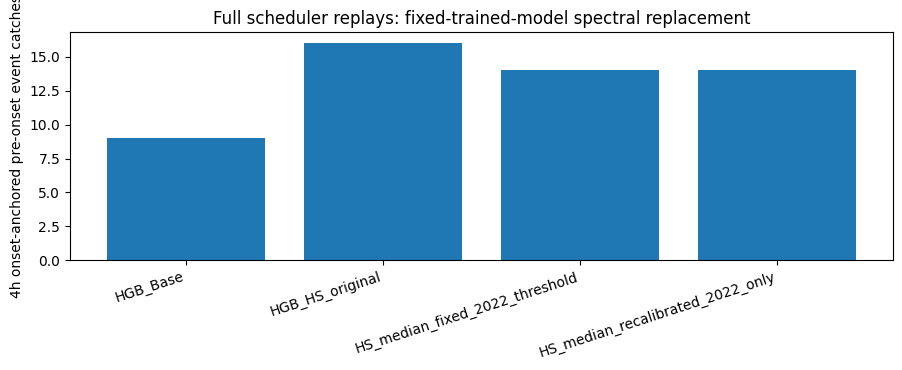

In [10]:
MEDIAN_HS=float(np.median(X[TRAIN,2]))
assert np.isfinite(MEDIAN_HS)
SCORE_NEUTRAL=np.full(len(T),np.nan,dtype=np.float64)
idx_cf=np.flatnonzero(CAL|DEV)
for block in np.array_split(idx_cf,max(1,int(np.ceil(len(idx_cf)/140000)))):
    if not len(block):continue
    xx=X[block].copy()
    xx[:,2]=MEDIAN_HS
    SCORE_NEUTRAL[block]=HGB_HS.predict_proba(xx)[:,1]
assert np.isfinite(SCORE_NEUTRAL[CAL|DEV]).all()
CF_THR_2022,CF_CAL_EVENTS,CF_SEARCH=calibrate(T_CAL,SCORE_NEUTRAL[CAL])
CF_POLICIES={
 'HGB_Base':(ALARMS['HGB_Base'],THR['HGB_Base'],CAL_COUNTS['HGB_Base']),
 'HGB_HS_original':(ALARMS['HGB_HS'],THR['HGB_HS'],CAL_COUNTS['HGB_HS']),
 'HS_median_fixed_2022_threshold':(
    scheduler(T_DEV,SCORE_NEUTRAL[DEV],THR['HGB_HS']),THR['HGB_HS'],
    len(scheduler(T_CAL,SCORE_NEUTRAL[CAL],THR['HGB_HS']))),
 'HS_median_recalibrated_2022_only':(
    scheduler(T_DEV,SCORE_NEUTRAL[DEV],CF_THR_2022),CF_THR_2022,CF_CAL_EVENTS)
}
CF_ROWS=[]
cf_hit={}
for name,(alerts,threshold,ncal) in CF_POLICIES.items():
    for anchor in ['onset','breach']:
        events=EVAL_ON[240] if anchor=='onset' else EVAL[240]
        hits=event_catches(events,alerts,anchor).set_index('event_id').hit
        cf_hit[(name,anchor)]=hits
        CF_ROWS.append(dict(policy=name,anchor=anchor,alerts=len(alerts),calibration_2022_alerts=ncal,
            threshold=threshold,pre_catches=int(hits.sum()),catches_per_100_alerts=
            100*int(hits.sum())/len(alerts) if len(alerts) else np.nan))
CF_TABLE=pd.DataFrame(CF_ROWS)
CF_TABLE.to_csv(OUT/'49_3_full_scheduler_counterfactual.csv',index=False)
CF_SEARCH.to_csv(OUT/'49_3_2022_neutral_threshold_grid.csv',index=False)

base=cf_hit[('HGB_Base','onset')];original=cf_hit[('HGB_HS_original','onset')]
assert int(base.sum())==9 and int(original.sum())==16
cf_event_rows=[]
for eid in EVAL_ON[240].event_id:
    row=dict(event_id=int(eid),hgb_base_hit=bool(base.loc[eid]),hgb_hs_original_hit=bool(original.loc[eid]))
    for name in ['HS_median_fixed_2022_threshold','HS_median_recalibrated_2022_only']:
        row[name+'_hit']=bool(cf_hit[(name,'onset')].loc[eid])
    row['47_new_only_event']=bool(original.loc[eid] and not base.loc[eid])
    row['hs_original_lost_if_spectral_neutral_fixed']=bool(original.loc[eid] and not cf_hit[('HS_median_fixed_2022_threshold','onset')].loc[eid])
    row['hs_original_lost_if_spectral_neutral_recal']=bool(original.loc[eid] and not cf_hit[('HS_median_recalibrated_2022_only','onset')].loc[eid])
    cf_event_rows.append(row)
CF_EVENTS=pd.DataFrame(cf_event_rows)
CF_EVENTS.to_csv(OUT/'49_3_event_level_counterfactual.csv',index=False)

# Separate rate and event difference; equal alert counts are not assumed.
CF_COMPARE=[]
for name in ['HS_median_fixed_2022_threshold','HS_median_recalibrated_2022_only']:
    h0=cf_hit[('HGB_HS_original','onset')];h1=cf_hit[(name,'onset')]
    CF_COMPARE.append(dict(policy=name,original_onset_hits=int(h0.sum()),neutral_onset_hits=int(h1.sum()),
       original_only=int((h0&~h1).sum()),neutral_only=int((h1&~h0).sum()),
       among_original_eight_rescues_maintained=int((original&~base &h1).sum()),
       among_original_eight_rescues_lost=int((original&~base &~h1).sum()),
       original_alerts=len(CF_POLICIES['HGB_HS_original'][0]),neutral_alerts=len(CF_POLICIES[name][0])))
CF_COMPARE=pd.DataFrame(CF_COMPARE)
CF_COMPARE.to_csv(OUT/'49_3_eight_rescue_counterfactual_fates.csv',index=False)
print('2021 median z_hs:',MEDIAN_HS)
print('Full 2022-calibration + development replay:');display(CF_TABLE)
print('What happens to the 8 rescued events?');display(CF_COMPARE)

# Supporting visual: retain neutral (unstandardized) color choices.
fig,ax=plt.subplots(figsize=(9,3.8))
z=CF_TABLE.loc[CF_TABLE.anchor=='onset']
ax.bar(range(len(z)),z.pre_catches)
ax.set_xticks(range(len(z)),labels=z.policy,rotation=18,ha='right')
ax.set_ylabel('4h onset-anchored pre-onset event catches')
ax.set_title('Full scheduler replays: fixed-trained-model spectral replacement')
fig.tight_layout()
fig.savefig(OUT/'49_3_full_scheduler_onset_catches.png',dpi=165,bbox_inches='tight')
plt.show()


## Experiment 4A. Later period already seen in other research (optional retrospective stress test)

I designed this experiment to apply the frozen models to May to November 2026 without fitting to those outcomes. The spot cache this notebook reads ends on 2026-05-01 (notebooks 07 and 27 downloaded later months separately), so the stored report has the status `NOT_AVAILABLE`. Because I examined part of May to September 2026 earlier, the period is not an independent holdout, and I label the report `previously_inspected_retrospective_stress`. With data, the report gives the primary breach-anchored outcome of notebook 47 together with the descriptive onset-anchored catches, and I classify a short period with no or very few crashes as `INCONCLUSIVE`.

In [11]:
STRESS_START=pd.Timestamp('2026-05-01T00:00:00Z')
STRESS_END_LIMIT=pd.Timestamp('2026-12-01T00:00:00Z')
AVAILABLE_STOP=pd.Timestamp(int(T[-1]),tz='UTC')+pd.Timedelta(minutes=1)
STRESS_STOP=min(STRESS_END_LIMIT,AVAILABLE_STOP)
STRESS_REPORT={'status':'NOT_AVAILABLE','label':'previously_inspected_retrospective_stress',
    'never_treat_as_unused_holdout':True,
    'observed_cache_stop_utc':str(AVAILABLE_STOP),
    'period_start_utc':str(STRESS_START),'period_end_exclusive_utc':str(STRESS_STOP)}
if STRESS_STOP-STRESS_START>=pd.Timedelta(days=7):
    min_ts=STRESS_START+pd.Timedelta(minutes=LEAD_MAX+5)
    max_ts=STRESS_STOP-pd.Timedelta(minutes=5)
    later_events=CAT[240][(CAT[240].breach_utc>=min_ts)&(CAT[240].breach_utc<max_ts)].copy()
    later_onset=later_events[later_events.onset_1pct_utc>=min_ts].copy()
    # Calendar scheduler begins at the start of the available stress period; no 2023-26 development re-calibration.
    stress_valid=(valid&(T>=STRESS_START.value)&(T<STRESS_STOP.value))
    later_t=T[stress_valid]
    later_x=X[stress_valid]
    if len(later_t):
        later_score_b=HGB_BASE.predict_proba(later_x[:,:2])[:,1]
        later_score_h=HGB_HS.predict_proba(later_x)[:,1]
        later_alert_b=scheduler(later_t,later_score_b,THR['HGB_Base'])
        later_alert_h=scheduler(later_t,later_score_h,THR['HGB_HS'])
        stress_rows=[]
        for model,aa in [('HGB_Base',later_alert_b),('HGB_HS',later_alert_h)]:
            for anchor,ev in [('breach',later_events),('onset',later_onset)]:
                hits=event_catches(ev,aa,anchor) if len(ev) else pd.DataFrame({'hit':[]})
                stress_rows.append(dict(period_start=str(STRESS_START),period_stop=str(STRESS_STOP),
                   model=model,anchor=anchor,events=len(ev),alerts=len(aa),hits=int(hits.hit.sum()),
                   catches_per_100_alerts=100*hits.hit.sum()/len(aa) if len(aa) else np.nan,
                   label='previously_inspected_retrospective_stress'))
        STRESS_TABLE=pd.DataFrame(stress_rows)
        STRESS_TABLE.to_csv(OUT/'49_4a_retrospective_stress.csv',index=False)
        STRESS_REPORT.update(status='RAN_NOT_INDEPENDENT',observed_events=len(later_events),
           onset_eligible_events=len(later_onset),summary_file='49_4a_retrospective_stress.csv')
        if len(later_events)<10:STRESS_REPORT['inference']='INCONCLUSIVE_FEW_EVENTS'
        else:STRESS_REPORT['inference']='DESCRIPTIVE_ONLY_ALREADY_INSPECTED'
        display(STRESS_TABLE)
(OUT/'49_4a_status.json').write_text(json.dumps(STRESS_REPORT,indent=2,default=str))
print(json.dumps(STRESS_REPORT,indent=2,default=str))


{
  "status": "NOT_AVAILABLE",
  "label": "previously_inspected_retrospective_stress",
  "never_treat_as_unused_holdout": true,
  "observed_cache_stop_utc": "2026-05-01 00:00:00+00:00",
  "period_start_utc": "2026-05-01 00:00:00+00:00",
  "period_end_exclusive_utc": "2026-05-01 00:00:00+00:00"
}


## Experiment 4B. Independent unused post-registration evaluation on future data

In this experiment I apply only the 2021-trained HGB Base and HGB+HS models, with their 2022-calibrated fixed thresholds, once to BTC spot data after `2027-12-01T00:00:00Z`: one-minute prices and the `z_vol`, `tsr` and `z_hs` signals in `49_optional_independent_holdout/`, with a manifest recording their provenance and the analysis window. No independent result exists until such data do.

In [12]:
def sha256_file(p,block_bytes=4*1024*1024):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        while True:
            chunk=f.read(block_bytes)
            if not chunk:break
            h.update(chunk)
    return h.hexdigest()

HOLDOUT_DIR=ROOT/'49_optional_independent_holdout'
HOLDOUT_REQUIRED={
  'price':HOLDOUT_DIR/'price_1m.parquet',
  'signals':HOLDOUT_DIR/'signals_1m.parquet',
  'manifest':HOLDOUT_DIR/'HOLDOUT_MANIFEST.json'}
INDEPENDENT_RESULT_PATH=OUT/'49_4b_independent_result.json'
INDEPENDENT_LOCK=OUT/'49_4b_LOCK.sha256'
INDEPENDENT_REPORT={
 'status':'PENDING_TRUE_HOLDOUT',
 'reason':'An untouched genuinely independent dataset outside previous development, prior inspected holdouts, and the separate prospective registration has not been supplied.',
 'prospective_registration_reserved_interval_utc':'2026-12-01 to 2027-12-01',
 'earliest_permitted_independent_start_utc':'2027-12-01T00:00:00Z',
 'previously_inspected_period_is_not_independent':True,
 'original_primary_47_screen':'FAILED'}

def analyze_future_untouched():
    missing=[str(p) for p in HOLDOUT_REQUIRED.values() if not p.exists()]
    if missing:
        return dict(INDEPENDENT_REPORT,missing_input_files=missing)
    if INDEPENDENT_LOCK.exists():
        if not INDEPENDENT_RESULT_PATH.exists():
            raise RuntimeError('The independent lock exists but the result is missing; check the folder before running again and keep the lock')
        return json.loads(INDEPENDENT_RESULT_PATH.read_text())
    manifest=json.loads(HOLDOUT_REQUIRED['manifest'].read_text())
    assert manifest.get('never_previously_inspected') is True,'Attested never-inspected condition missing'
    assert manifest.get('no_overlap_with_prospective_registration') is True,'Prospective overlap audit missing'
    assert manifest.get('venue')=='Binance BTCUSDT spot','No BTC futures or cross-venue substitution'
    for kind in ('price','signals'):
        expected=manifest.get('sha256_'+kind)
        assert isinstance(expected,str) and len(expected)==64,kind+' SHA-256 manifest missing'
        observed=sha256_file(HOLDOUT_REQUIRED[kind])
        assert observed.lower()==expected.lower(),kind+' SHA-256 mismatch'
    start=pd.Timestamp(manifest['analysis_start_utc']).tz_convert('UTC')
    stop=pd.Timestamp(manifest['analysis_end_exclusive_utc']).tz_convert('UTC')
    assert start>=pd.Timestamp('2027-12-01T00:00:00Z'), 'Do not access registered prospective window or previously examined data'
    assert stop>start+pd.Timedelta(days=1)
    newp=pd.read_parquet(HOLDOUT_REQUIRED['price']).sort_index()
    news=pd.read_parquet(HOLDOUT_REQUIRED['signals'],columns=['z_vol','tsr','z_hs']).sort_index()
    for d in (newp,news):
        assert isinstance(d.index,pd.DatetimeIndex) and d.index.tz is not None
        d.index=d.index.tz_convert('UTC')
    assert newp.index.equals(news.index)
    htt=newp.index.asi8
    assert len(htt)>2000 and np.all(np.diff(htt)==NS),'Independent data need contiguous UTC 1m bars'
    assert pd.Timestamp(int(htt[0]),tz='UTC')>=pd.Timestamp('2027-12-01T00:00:00Z')
    assert pd.Timestamp(int(htt[0]),tz='UTC')<=start-pd.Timedelta(minutes=245),'Insufficient pre-start lookback'
    assert pd.Timestamp(int(htt[-1]),tz='UTC')>=stop-pd.Timedelta(minutes=1),'Data end is too early'
    if int(htt[0])<=int(T[-1]):raise RuntimeError('Independent observations overlap existing development cache')
    assert {'close','volume'}.issubset(newp.columns)
    xx=news[['z_vol','tsr','z_hs']].to_numpy(dtype=float)
    cc=newp.close.to_numpy(dtype=float);vv=newp.volume.to_numpy(dtype=float)
    good=(np.isfinite(cc)&(cc>0)&np.isfinite(vv)&(vv>0)&
          np.isfinite(xx).all(axis=1)&(xx[:,1]>=0)&(xx[:,1]<=1))
    cat_future=price_only_catalog(cc,vv,newp.index,H=240)
    ev=cat_future[(cat_future.breach_utc>=start+pd.Timedelta(minutes=LEAD_MAX+5))&
                  (cat_future.breach_utc<stop-pd.Timedelta(minutes=5))].copy()
    ev_on=ev[ev.onset_1pct_utc>=start+pd.Timedelta(minutes=LEAD_MAX+5)].copy()
    # Derive candidate scores from the frozen 2021-trained estimators, then schedule
    # on the full supplied grid to preserve all earlier cooldown/month state.
    z={}
    for model,mdl,features in [('HGB_Base',HGB_BASE,xx[:,:2]),('HGB_HS',HGB_HS,xx)]:
        valid_idx=np.flatnonzero(good)
        sc=np.full(len(htt),np.nan)
        for batch in np.array_split(valid_idx,max(1,int(np.ceil(len(valid_idx)/150000)))):
            if len(batch):sc[batch]=mdl.predict_proba(features[batch])[:,1]
        al=scheduler(htt,sc,THR[model])
        al=al[(al>=start.value)&(al<stop.value)]
        z[model]=al
    out=[]
    for model,alarms in z.items():
        for anch,ee in [('breach',ev),('onset',ev_on)]:
            hits=event_catches(ee,alarms,anch) if len(ee) else pd.DataFrame({'hit':[]})
            out.append(dict(model=model,anchor=anch,events=len(ee),alerts=len(alarms),
                            pre_onset_catches=int(hits.hit.sum()),
                            catches_per_100_alerts=100*hits.hit.sum()/len(alarms) if len(alarms) else None))
    out_df=pd.DataFrame(out)
    out_df.to_csv(OUT/'49_4b_independent_comparison.csv',index=False)
    result=dict(status='RAN_OPERATOR_ATTESTED_INDEPENDENT',
      inference='DESCRIPTIVE_ONE_SHOT; confidence and any new hypothesis require a separately frozen plan',
      start_utc=str(start),end_utc=str(stop),total_events=len(ev),eligible_onset_events=len(ev_on),
      manifest_sha256=sha256_file(HOLDOUT_REQUIRED['manifest']),rows=out,
      previously_inspected_period_is_not_independent=True,
      original_primary_47_screen='FAILED',
      operator_attestation_cannot_be_verified_by_code=True)
    # Save JSON then immutable-by-convention one-shot lock (no results were selected/tuned here).
    INDEPENDENT_RESULT_PATH.write_text(json.dumps(result,indent=2,default=str))
    INDEPENDENT_LOCK.write_text(sha256_file(INDEPENDENT_RESULT_PATH)+'  49_4b_independent_result.json\n')
    return result

INDEPENDENT_REPORT=analyze_future_untouched()
(OUT/'49_4b_status.json').write_text(json.dumps(INDEPENDENT_REPORT,indent=2,default=str))
print(json.dumps(INDEPENDENT_REPORT,indent=2,default=str))


{
  "status": "PENDING_TRUE_HOLDOUT",
  "reason": "An untouched genuinely independent dataset outside previous development, prior inspected holdouts, and the separate prospective registration has not been supplied.",
  "prospective_registration_reserved_interval_utc": "2026-12-01 to 2027-12-01",
  "earliest_permitted_independent_start_utc": "2027-12-01T00:00:00Z",
  "previously_inspected_period_is_not_independent": true,
  "original_primary_47_screen": "FAILED",
  "missing_input_files": [
    "/content/drive/MyDrive/btc_lead_cost_results_77months_spot/49_optional_independent_holdout/price_1m.parquet",
    "/content/drive/MyDrive/btc_lead_cost_results_77months_spot/49_optional_independent_holdout/signals_1m.parquet",
    "/content/drive/MyDrive/btc_lead_cost_results_77months_spot/49_optional_independent_holdout/HOLDOUT_MANIFEST.json"
  ]
}


## Specification and summary

The primary breach-anchored HGB spectral screen of notebook 47 failed; experiments 1–3 measure the mechanism of one post hoc onset-anchored gain and do not turn it into confirmed incremental predictability. Experiment 4A, if present, covers previously inspected data and is descriptive, and experiment 4B stays `PENDING_TRUE_HOLDOUT` until a demonstrably separate source exists. I report fixed-threshold and recalibrated results separately; fixed-input median replacement is not a causal counterfactual, and matching two alert streams within 30 minutes is not a pre-onset event success.

In [13]:
S49={
 'notebook':'49','status':'exploratory_posthoc_mechanism_plus_conditional_independent',
 'source':'BTC spot frozen 47/48 inputs',
 'original_47_primary':'4h breach-anchored HGB Base vs HGB_HS; spectral fails +0.02 AUC and +0.5 catch /100 alert screen',
 'selected_secondary':'4h onset-anchored 9 vs 16, selected after viewing development results',
 'fixed_training':'2021','fixed_threshold_calibration':'2022 unlabeled',
 'development':'2023-01 through 2026-04',
 'tie_policy':'>= original; > using nextafter cut-off; no development retuning',
 'match_tolerances_minutes':[0,5,15,30,60],
 'spectral_replacement':'2021 z_hs median, all 2022 and dev timestamps; fixed and 2022 recalibrated threshold',
 'later_inspected':'2026-05 through before 2026-12 when available; never an independent holdout',
 'excluded_future_registration':'2026-12-01 through 2027-12-01',
 'genuine_independent_gate':'separate never-inspected, hash-attested BTC spot parquet from 2027-12-01 onward, if later available',
 'no_tuning_on_2023_2026_outcomes':True,
 'model_hyperparameters':SPEC['HGB'],
 'eight_original_47_new_only_rescues':8,
 'primary_report_all_results':True
}
(OUT/'49_SPEC.json').write_text(json.dumps(S49,indent=2,default=str))
summary={
 'notebook':'49','status':'exploratory_diagnostics',
 'reproduction_guards':{'onset_HGB_Base':n_hit(240,'HGB_Base','onset'),
   'onset_HGB_HS':n_hit(240,'HGB_HS','onset'),
   'breach_HGB_Base':n_hit(240,'HGB_Base','breach'),
   'breach_HGB_HS':n_hit(240,'HGB_HS','breach'),
   'base_alerts':len(ALARMS['HGB_Base']),'hs_alerts':len(ALARMS['HGB_HS'])},
 'experiment_1':{'plateau_table':'49_1_score_plateaus.csv',
   'threshold_replay':'49_1_strict_threshold_replay.csv',
   'rescue_on_threshold':int(rescues.hs_score_exactly_at_threshold.sum()),
   'strict_cutoff_note':'strict > may reduce number of alerts; not equal-budget'},
 'experiment_2':TIME_MATCH.to_dict(orient='records'),
 'experiment_3':{'2021_median_z_hs':MEDIAN_HS,
   'full_scheduler_policy':CF_TABLE.to_dict(orient='records'),
   'eight_event_fates':CF_COMPARE.to_dict(orient='records'),
   'causal_effect_established':False},
 'experiment_4a':STRESS_REPORT,
 'experiment_4b':INDEPENDENT_REPORT,
 'no_confirmatory_claim':True,
 'interpretation':'Post-hoc exploratory diagnostic. Original primary HGB spectral screen negative; secondary onset win not independent validation.'
}
(OUT/'49_SUMMARY.json').write_text(json.dumps(summary,indent=2,default=str))
print('Saved 49_SPEC.json and 49_SUMMARY.json')
print('Output directory:',OUT)
print('Independent holdout status:',INDEPENDENT_REPORT['status'])
print('All four experiments are reported: completed, not available or pending.')


Saved 49_SPEC.json and 49_SUMMARY.json
Output directory: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/spectral_mechanism_four_tests_v1
Independent holdout status: PENDING_TRUE_HOLDOUT
All four experiments are reported: completed, not available or pending.
